In [1]:
import scanpy as sc

# Tải dữ liệu PBMC 3k trực tiếp từ server của 10x Genomics (chỉ tốn ~6MB)
adata = sc.datasets.pbmc3k()

# Kiểm tra kích thước ma trận (Số tế bào x Số gene)
print(adata)
# Kết quả: AnnData object with n_obs × n_vars = 2700 × 32738

d:\Duy_Project\Bioinfomatician\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)


In [2]:
import pandas as pd

# 1. Xem danh sách 5 tế bào đầu tiên (mã barcode của từng tế bào)
print("--- Thông tin tế bào (obs) ---")
display(adata.obs.head(100))

# 2. Xem danh sách 5 gene đầu tiên (tên gene và mã Ensembl ID)
print("--- Thông tin gene (var) ---")
display(adata.var.head(100))

# 3. Xem ma trận số đếm (5 tế bào đầu x 5 gene đầu) dưới dạng bảng Pandas dễ đọc
print("--- Ma trận biểu hiện gene (X) ---")
df_preview = adata[:100, :100].to_df()
display(df_preview)


--- Thông tin tế bào (obs) ---


""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1
...
AAGAGATGGGTAGG-1
AAGATGGAAAACAG-1
AAGATGGAGAACTC-1


--- Thông tin gene (var) ---


,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
RP1-140A9.1,ENSG00000231050
CALML6,ENSG00000169885
TMEM52,ENSG00000178821


--- Ma trận biểu hiện gene (X) ---


index,MIR1302-10,FAM138A,OR4F5,RP11-34P13.7,RP11-34P13.8,AL627309.1,RP11-34P13.14,RP11-34P13.9,AP006222.2,RP4-669L17.10,...,RP11-345P4.7,CDK11A,SLC35E2,NADK,GNB1,RP1-140A9.1,CALML6,TMEM52,C1orf222,RP11-547D24.1
index,,,,,,,,,,,,,,,,,,,,,
AAACATACAACCAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACATTGAGCTAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACATTGATCAGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGCTTCCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
AAACCGTGTATGCG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AAGAGATGGGTAGG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAGATGGAAAACAG-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAGATGGAGAACTC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# Xem các gene thực sự có biểu hiện (> 0) ở tế bào đầu tiên
cell_0 = adata[0, :].to_df().T
display(cell_0[cell_0.iloc[:, 0] > 0].head(10))

index,AAACATACAACCAC-1
index,
MRPL20,1.0
RPL22,1.0
TNFRSF25,2.0
EFHD2,1.0
NECAP2,1.0
AKR7A2,1.0
CAPZB,1.0
RPL11,41.0
RP5-886K2.3,1.0


In [4]:
import matplotlib.pyplot as plt

# Thiết lập thông số hiển thị hình ảnh sắc nét
sc.settings.verbosity = 3  # In ra chi tiết quá trình chạy
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

# Đảm bảo tên gene là duy nhất (tránh lỗi trùng tên sau này)
adata.var_names_make_unique()

# 1. Đánh dấu các gene ty thể (ở người, tên gene ty thể bắt đầu bằng 'MT-')
adata.var['mt'] = adata.var_names.str.startswith('MT-')

# 2. Tính toán các chỉ số QC cho từng tế bào và từng gene
# Kết quả sẽ tự động được lưu vào bảng adata.obs và adata.var
sc.pp.calculate_qc_metrics(
    adata, 
    qc_vars=['mt'], 
    percent_top=None, 
    log1p=False, 
    inplace=True
)

# Xem nhanh các cột chỉ số vừa được tạo thêm trong adata.obs
display(adata.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt']].head())

C:\Users\duy34\AppData\Local\Temp\ipykernel_20468\166748994.py:5: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=100, facecolor='white')
C:\Users\duy34\AppData\Local\Temp\ipykernel_20468\166748994.py:15: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(


,n_genes_by_counts,total_counts,pct_counts_mt
index,,,
AAACATACAACCAC-1,781,2421.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,1.743085
AAACCGTGTATGCG-1,522,981.0,1.223242


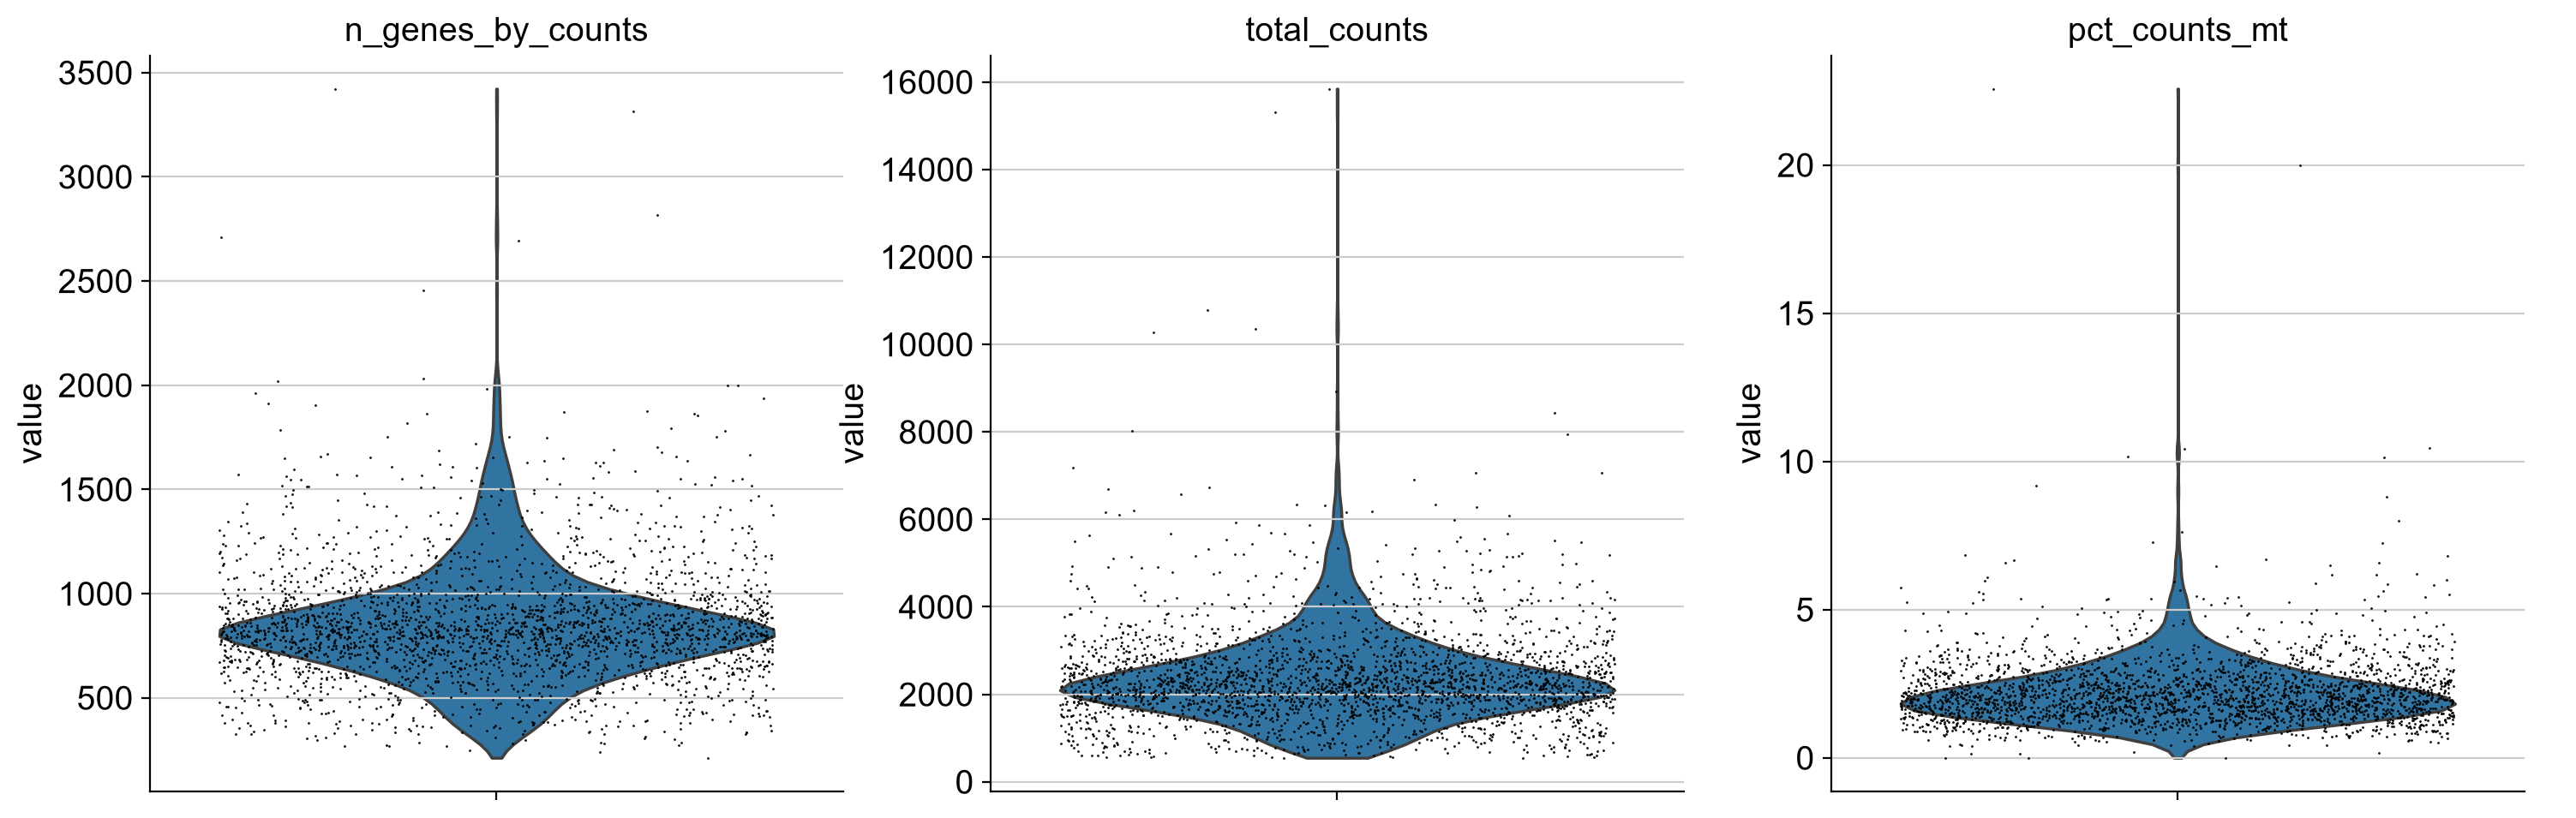

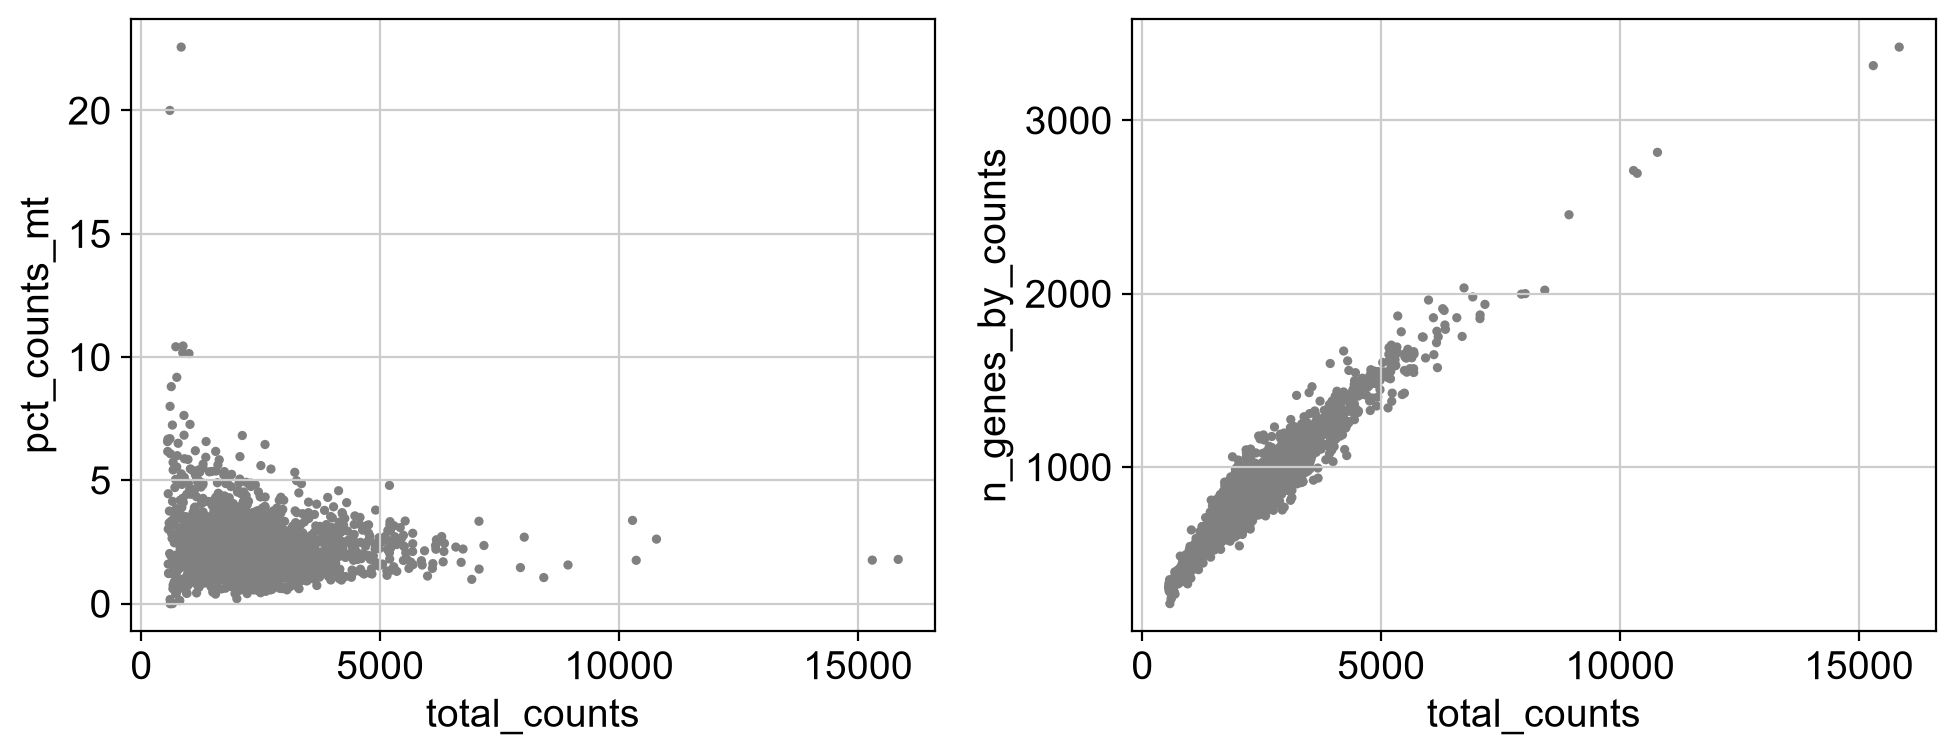

In [5]:
# 1. Vẽ Violin plot cho 3 chỉ số quan trọng nhất:
# - n_genes_by_counts: Số lượng gene phát hiện được trong mỗi tế bào
# - total_counts: Tổng số phân tử mRNA (UMI) trong mỗi tế bào
# - pct_counts_mt: Tỷ lệ phần trăm gene ty thể
sc.pl.violin(
    adata, 
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
    jitter=0.4, 
    multi_panel=True
)

# 2. Vẽ Scatter plot kiểm tra mối tương quan giữa tổng UMI với % MT và số lượng gene
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt', ax=axes[0], show=False)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', ax=axes[1], show=False)
plt.tight_layout()
plt.show()

In [6]:
print(f"Kích thước TRƯỚC khi lọc: {adata.shape[0]} tế bào × {adata.shape[1]} gene")

# 1. Lọc cơ bản:
# Giữ lại tế bào có ít nhất 200 gene biểu hiện
sc.pp.filter_cells(adata, min_genes=200)
# Giữ lại gene xuất hiện ở ít nhất 3 tế bào (loại bỏ hàng chục nghìn gene toàn số 0)
sc.pp.filter_genes(adata, min_cells=3)

# 2. Lọc theo ngưỡng dựa trên biểu đồ QC ở Cell 2:
# Loại bỏ tế bào nghi ngờ là doublet (> 2500 gene) và tế bào chết (>= 5% MT)
adata = adata[adata.obs.n_genes_by_counts < 2500, :]
adata = adata[adata.obs.pct_counts_mt < 5, :].copy()

print(f"Kích thước SAU khi lọc:   {adata.shape[0]} tế bào × {adata.shape[1]} gene")

Kích thước TRƯỚC khi lọc: 2700 tế bào × 32738 gene
filtered out 19024 genes that are detected in less than 3 cells
Kích thước SAU khi lọc:   2638 tế bào × 13714 gene


normalizing counts per cell
    finished (0:00:11)
extracting highly variable genes
    finished (0:00:06)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


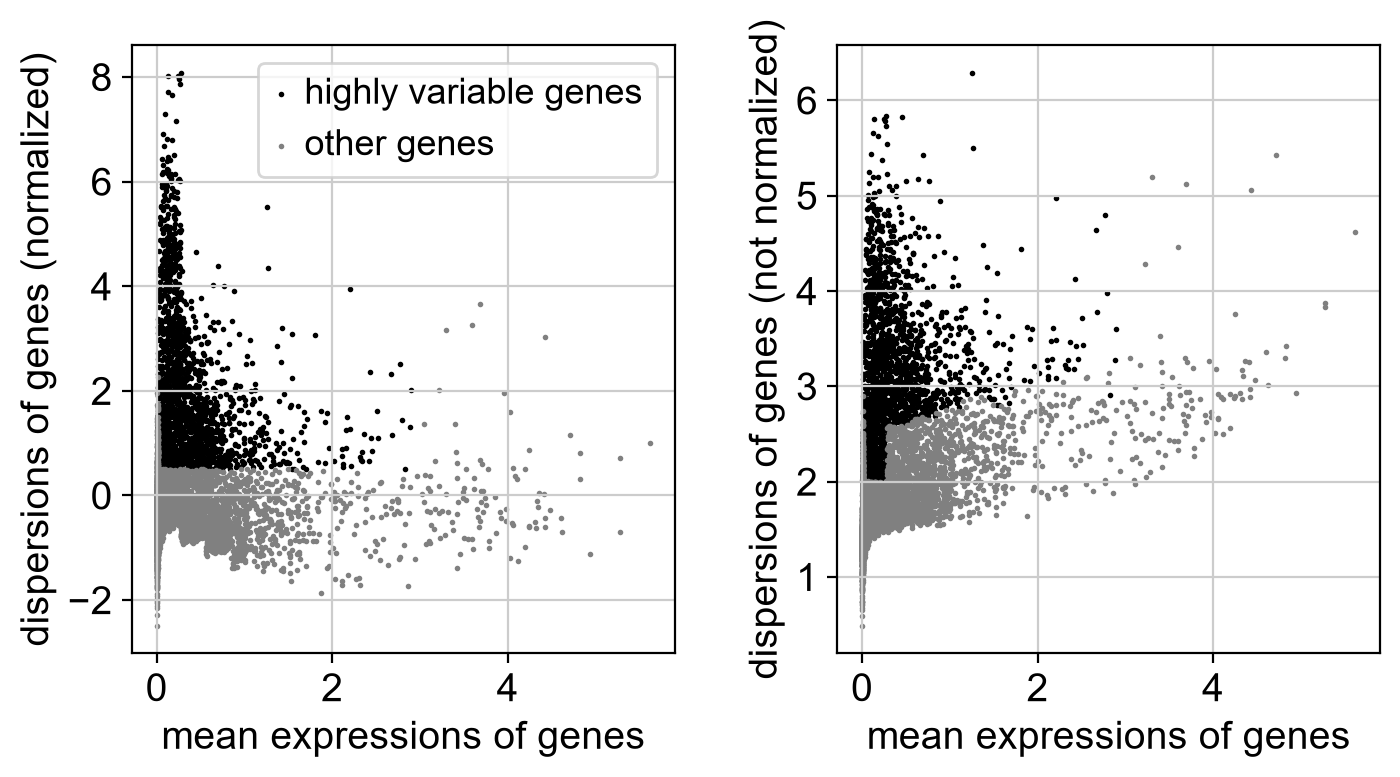

Số lượng Highly Variable Genes giữ lại: 1838


In [7]:
# 1. Chuẩn hóa tổng số đếm của mỗi tế bào về cùng mức 10,000 (loại bỏ chênh lệch kích thước thư viện)
sc.pp.normalize_total(adata, target_sum=1e4)

# 2. Biến đổi Logarit log(x + 1) để ổn định phương sai
sc.pp.log1p(adata)

# 3. Lưu lại bản sao toàn bộ 13,714 gene vào thuộc tính .raw 
# (Rất quan trọng: giúp bước sau vẫn vẽ được biểu đồ Marker Genes ngay cả khi đã cắt bớt gene)
adata.raw = adata

# 4. Tìm các Highly Variable Genes (HVGs) - những gene mang nhiều thông tin phân loại nhất
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

# Vẽ biểu đồ phân bố độ biến thiên của các gene
sc.pl.highly_variable_genes(adata)

# 5. Cắt ma trận, chỉ giữ lại các HVGs để đưa vào thuật toán PCA/Phân cụm
adata = adata[:, adata.var.highly_variable].copy()
print(f"Số lượng Highly Variable Genes giữ lại: {adata.shape[1]}")

regressing out ['total_counts', 'pct_counts_mt']
    sparse input is densified and may lead to high memory use


d:\Duy_Project\Bioinfomatician\myenv\Lib\site-packages\scanpy\preprocessing\_simple.py:595: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
d:\Duy_Project\Bioinfomatician\myenv\Lib\site-packages\scanpy\preprocessing\_simple.py:595: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


    finished (0:00:06)
computing PCA
    with n_comps=50
    finished (0:00:03)


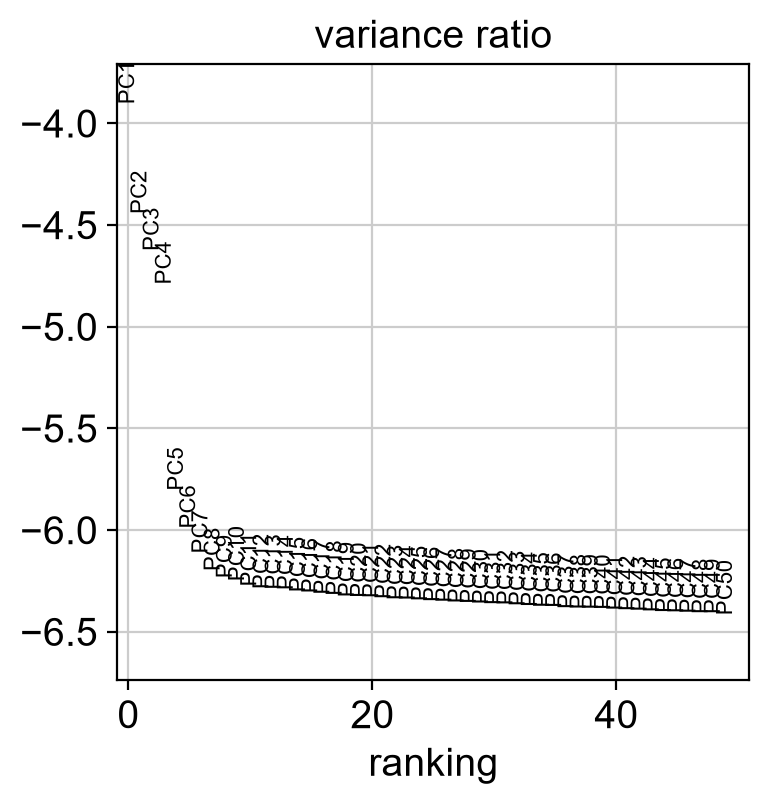

In [8]:
# 1. Hồi quy loại bỏ ảnh hưởng của tổng số UMI và % ty thể (tùy chọn chuẩn của Scanpy)
sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt'])

# 2. Đưa mỗi gene về trung bình = 0, độ lệch chuẩn = 1 (giới hạn max = 10 để tránh outlier kéo lệch PCA)
sc.pp.scale(adata, max_value=10)

# 3. Chạy PCA để nén dữ liệu xuống không gian ít chiều hơn
sc.tl.pca(adata, svd_solver='arpack')

# Vẽ biểu đồ Elbow (PCA variance ratio) để xem bao nhiêu thành phần chính (PC) là đủ
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=50)

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:01:27)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:10)


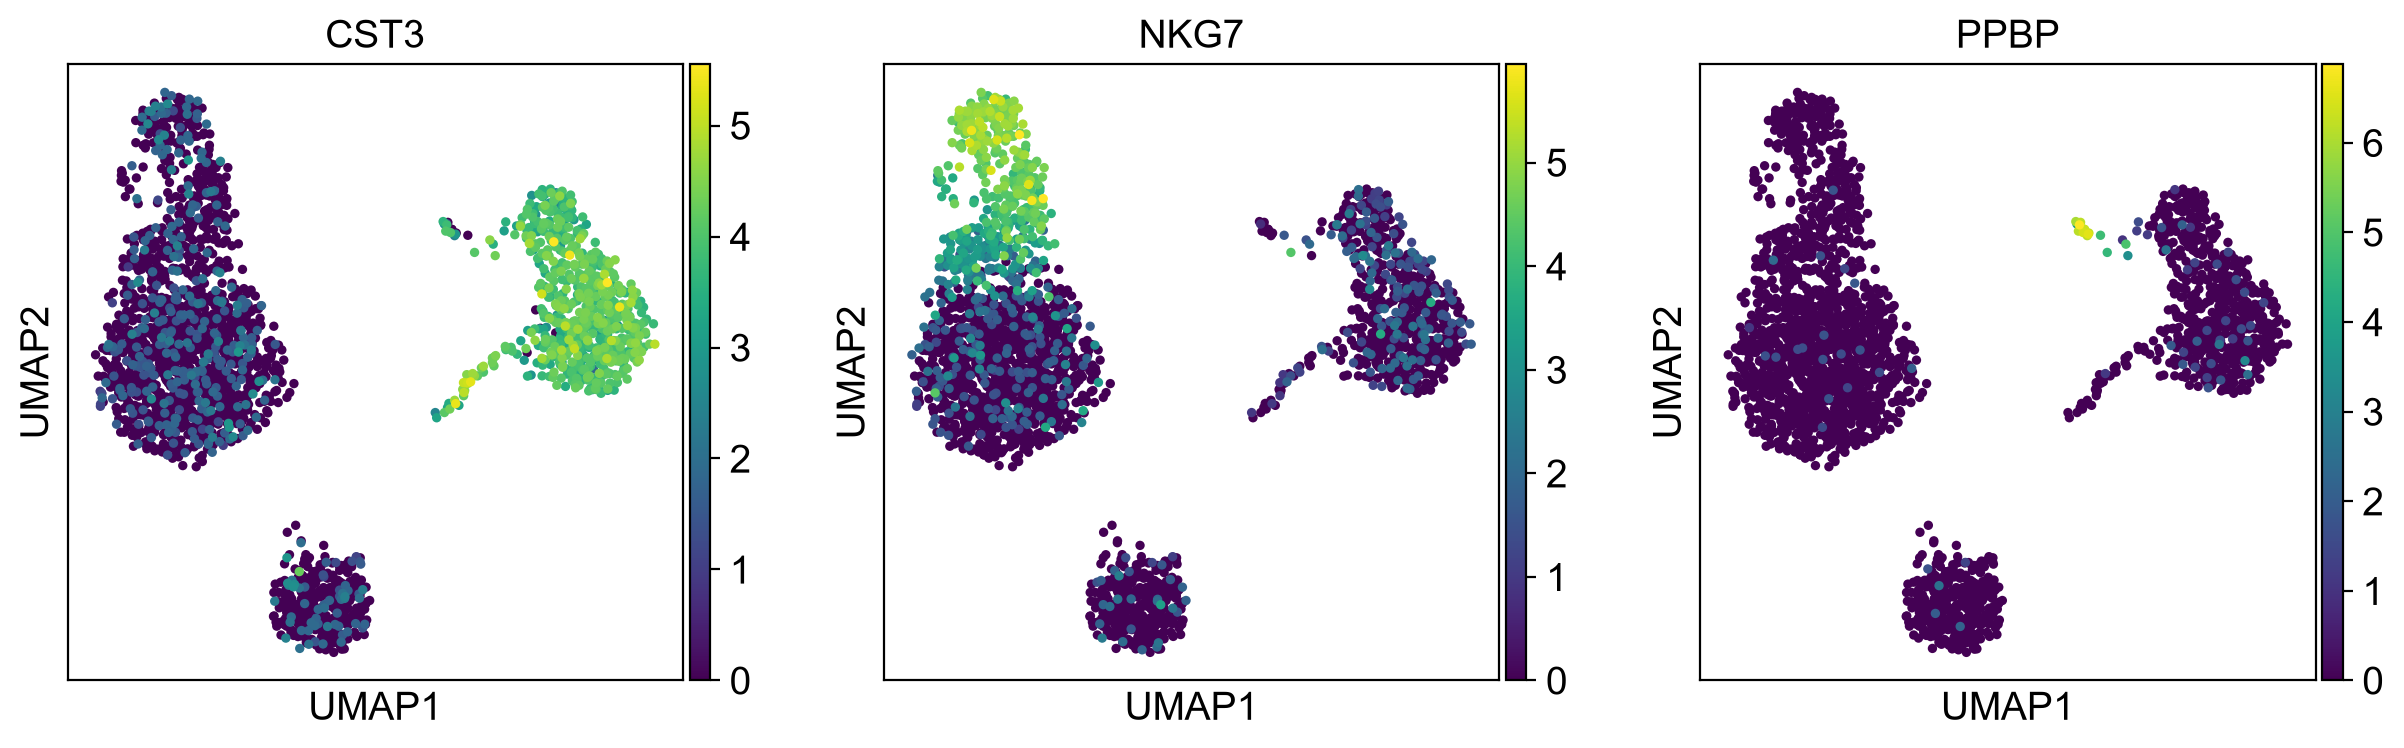

In [9]:
# 1. Xây dựng đồ thị lân cận dựa trên 10 thành phần PCA đầu tiên (dựa theo điểm gấp khúc của biểu đồ Elbow)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)

# 2. Tính toán tọa độ UMAP 2D để trực quan hóa
sc.tl.umap(adata)

# 3. Vẽ thử bản đồ UMAP và tô màu theo 3 marker gene kinh điển để kiểm tra sơ bộ
# (CST3: Monocytes, NKG7: NK/T cells, PPBP: Platelets)
sc.pl.umap(adata, color=['CST3', 'NKG7', 'PPBP'])

running Leiden clustering
    finished: found 6 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


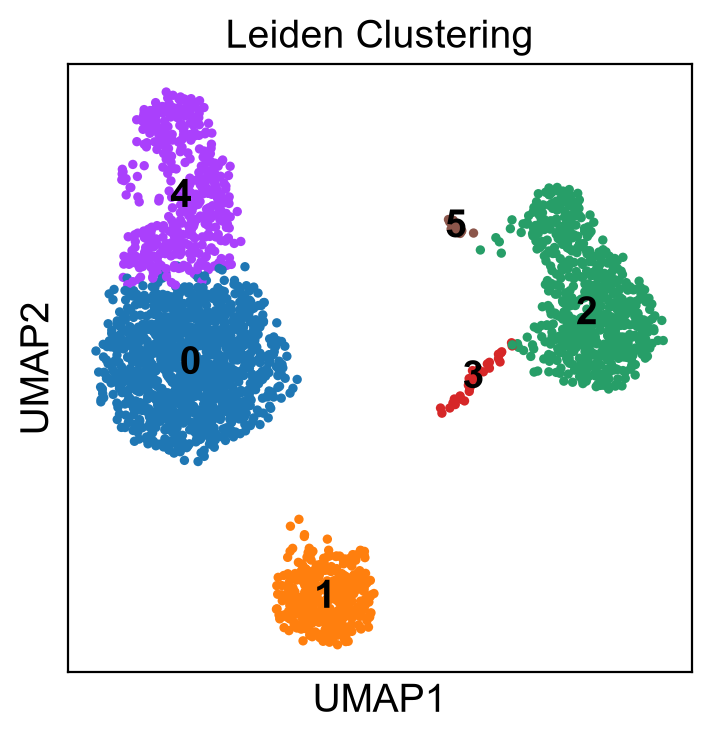

In [10]:
# Chạy phân cụm Leiden (resolution càng cao thì chia càng nhiều cụm nhỏ; 0.5–0.8 là mức chuẩn cho PBMC 3k)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2)

# Vẽ bản đồ UMAP với các cụm đã được đánh số (0, 1, 2...)
sc.pl.umap(adata, color=['leiden'], legend_loc='on data', title='Leiden Clustering')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:18)


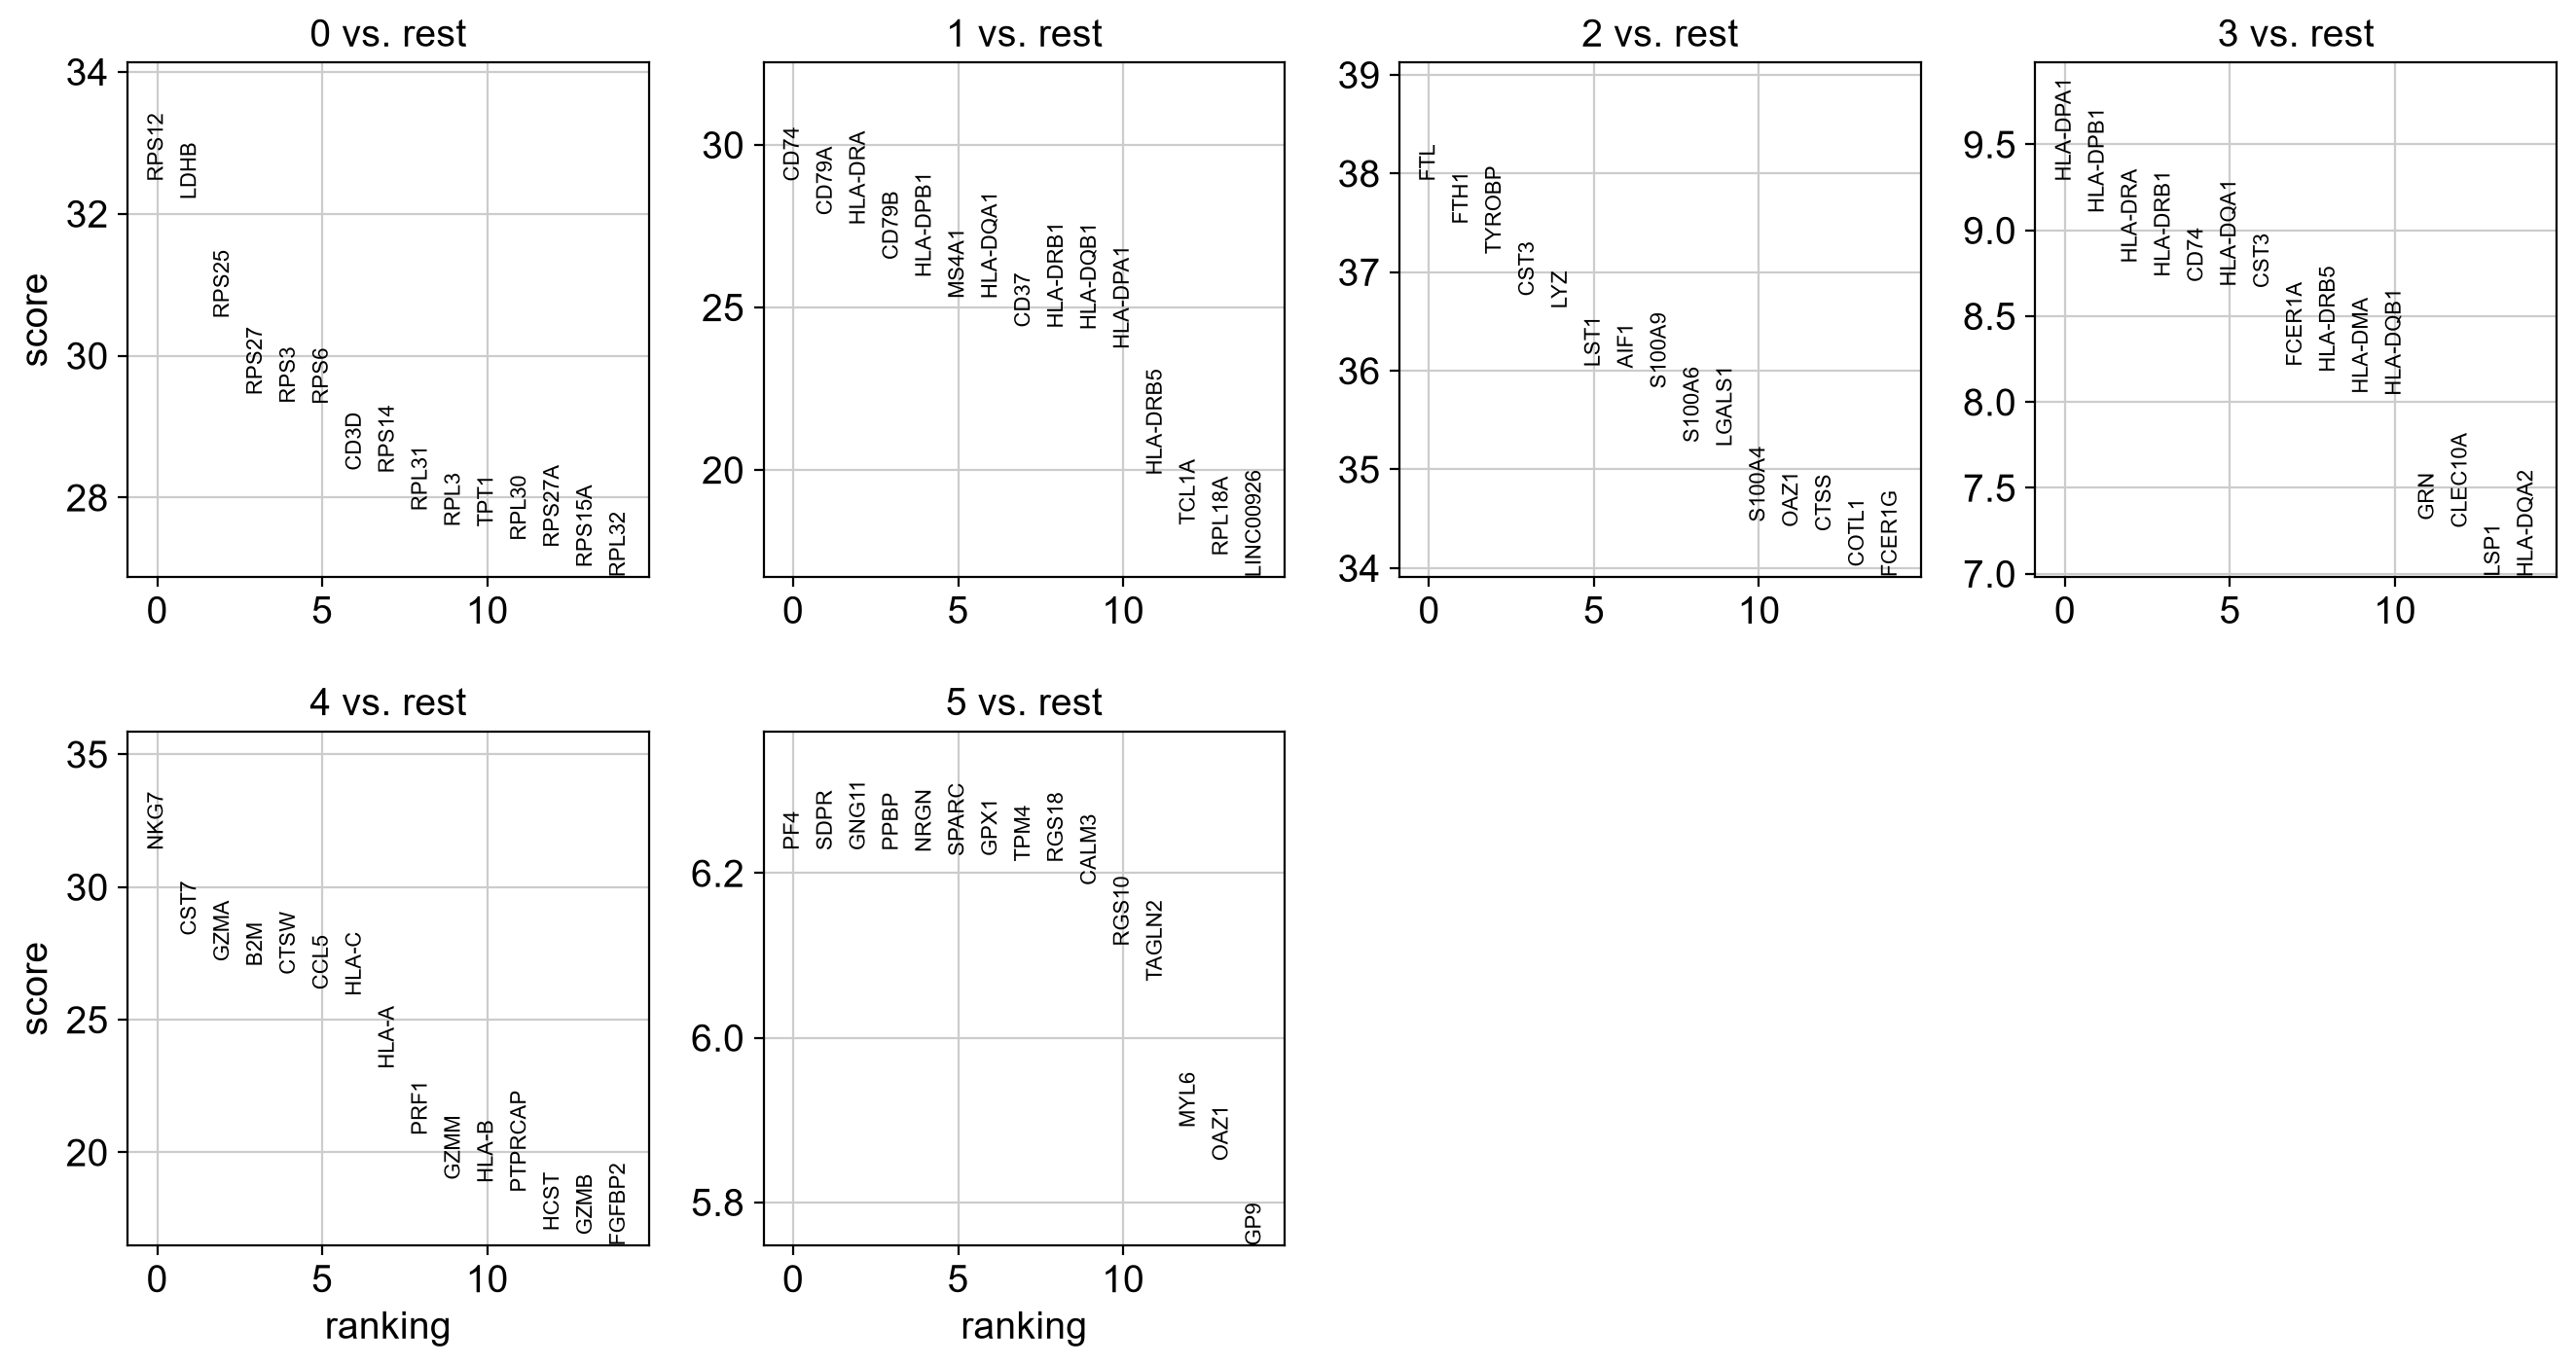

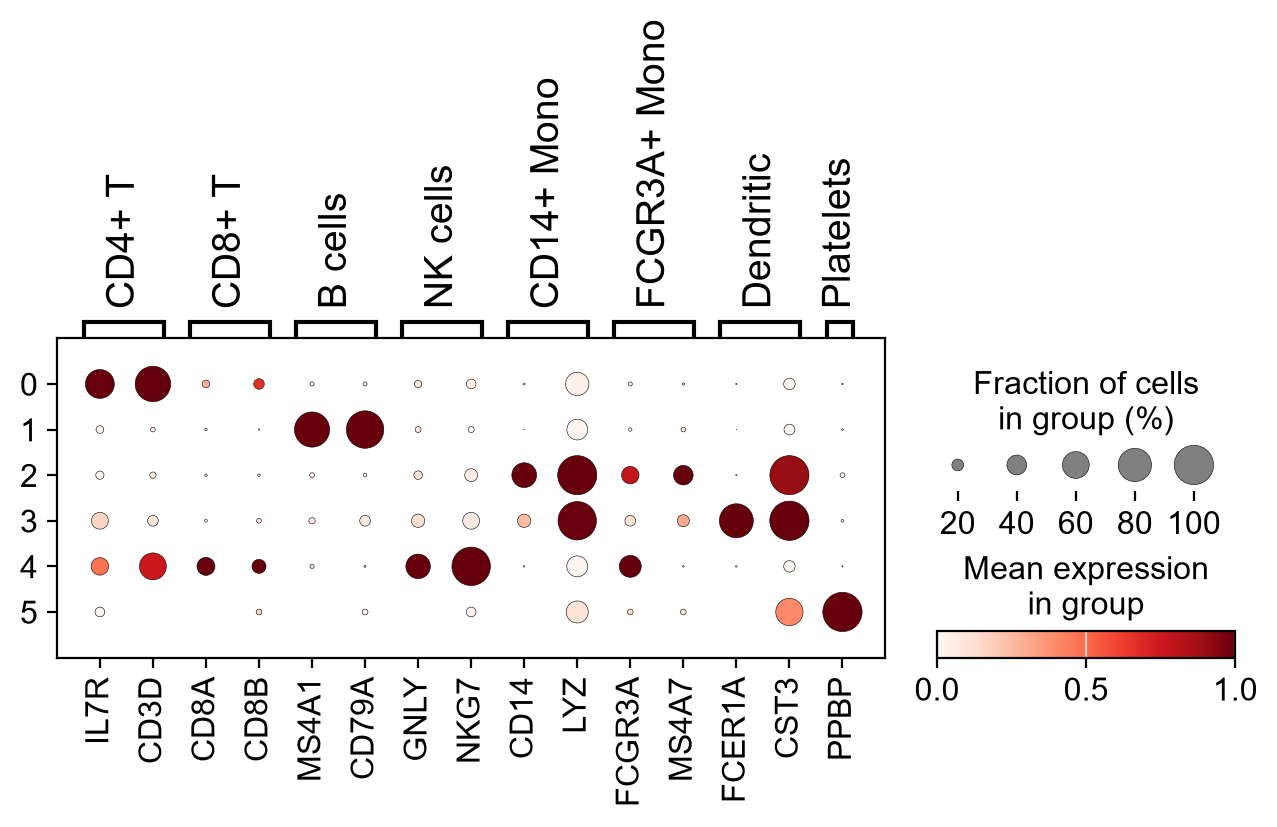

In [11]:
# 1. Tìm các gene biểu hiện khác biệt nhất cho từng cụm
sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
sc.pl.rank_genes_groups(adata, n_genes=15, sharey=False)

# 2. Vẽ DotPlot đối chiếu các Marker Genes chuẩn của tế bào miễn dịch
marker_genes = {
    'CD4+ T': ['IL7R', 'CD3D'],
    'CD8+ T': ['CD8A', 'CD8B'],
    'B cells': ['MS4A1', 'CD79A'],
    'NK cells': ['GNLY', 'NKG7'],
    'CD14+ Mono': ['CD14', 'LYZ'],
    'FCGR3A+ Mono': ['FCGR3A', 'MS4A7'],
    'Dendritic': ['FCER1A', 'CST3'],
    'Platelets': ['PPBP']
}

sc.pl.dotplot(adata, marker_genes, groupby='leiden', standard_scale='var')

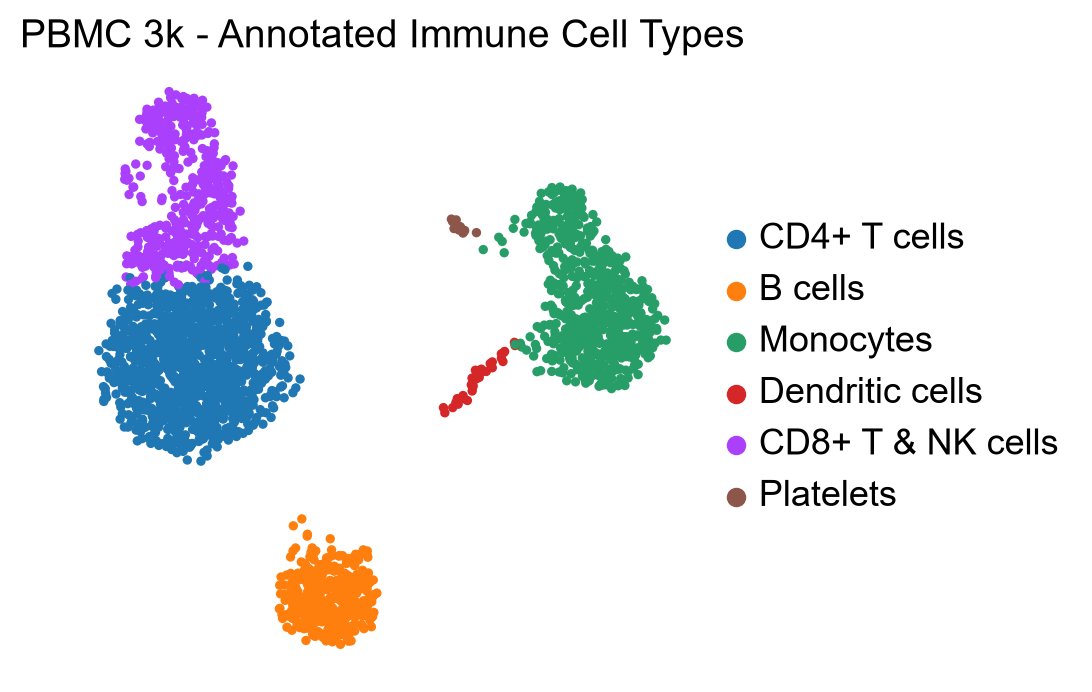

In [13]:
cluster_to_celltype = {
    '0': 'CD4+ T cells',
    '1': 'B cells',
    '2': 'Monocytes',
    '3': 'Dendritic cells',
    '4': 'CD8+ T & NK cells',
    '5': 'Platelets'
}

adata.obs['cell_type'] = adata.obs['leiden'].map(cluster_to_celltype)

# Vẽ bản đồ UMAP hoàn chỉnh (đưa chú thích sang bên phải để chữ không bị đè lên nhau)
sc.pl.umap(
    adata, 
    color='cell_type', 
    legend_loc='right margin', 
    frameon=False, 
    title='PBMC 3k - Annotated Immune Cell Types'
)

C:\Users\duy34\AppData\Local\Temp\ipykernel_20468\2848086984.py:5: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


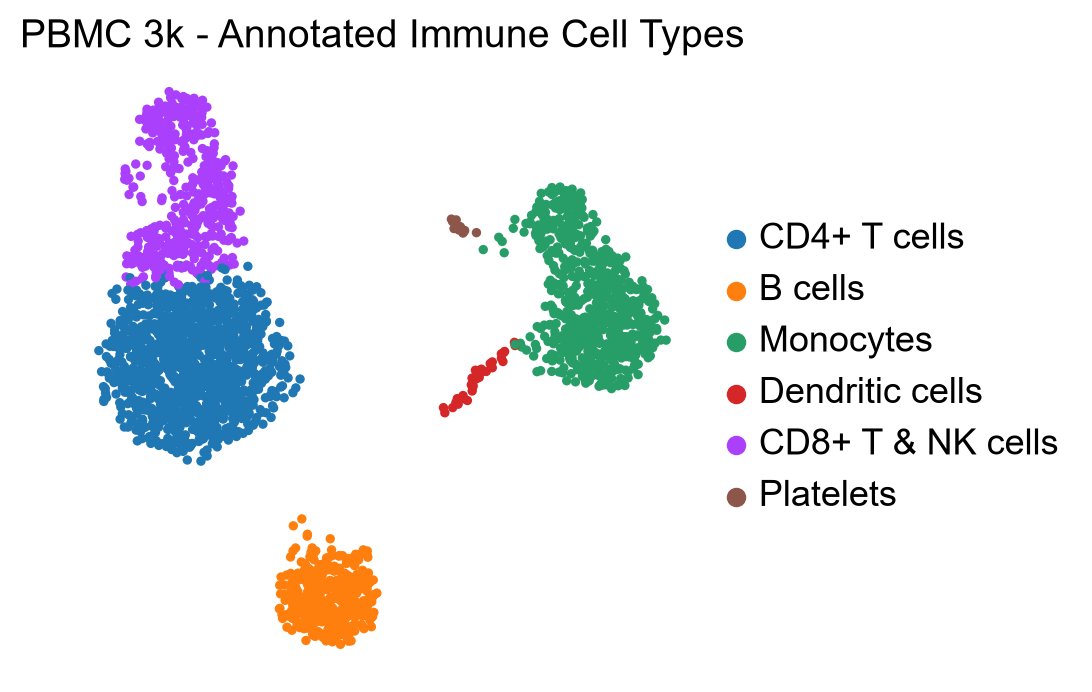

In [15]:
# 1. Lưu đối tượng AnnData đã làm sạch và gán nhãn ra file .h5ad
adata.write('data/pbmc3k_annotated.h5ad')

# 2. Xuất bản đồ UMAP độ phân giải cao (300 DPI) để chèn vào file README.md trên GitHub
sc.pl.umap(
    adata, 
    color='cell_type', 
    legend_loc='right margin', 
    frameon=False, 
    title='PBMC 3k - Annotated Immune Cell Types',
    save='_pbmc3k_annotated.png' # Ảnh sẽ tự động lưu vào thư mục figures/
)